In [1]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13)


mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")

annotate_sim_traj (generic function with 1 method)

### Generate simulation data

In [2]:
f(du,u,p,t) = (du[1] = log(2)/0.75*u[1])
rate(u,p,t) = 17/(1+exp(4.5*(4.7-u[1])))

function affect!(integrator)
   # symmetric division
   integrator.u[1] /= 2
end


u0 = [2.0]
vrj = VariableRateJump(rate, affect!)
oprob = ODEProblem(f, u0, (0.0,1000.0))
jprob = JumpProblem(oprob, Direct(), vrj)
sol = solve(jprob,Tsit5(),dtmax=0.01);

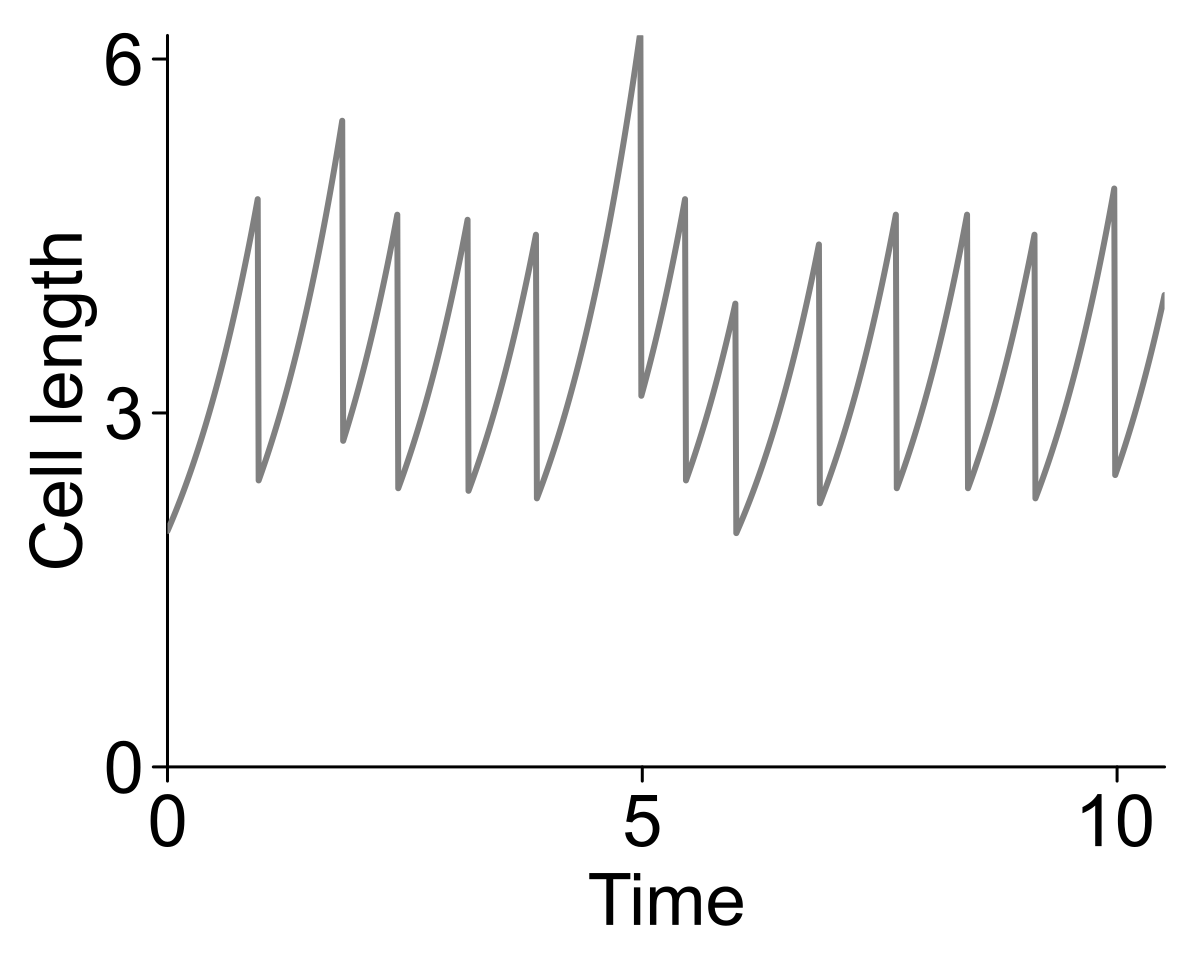

In [3]:
p0 = plot()
plot!(p0, sol, xlim=[0, 10.5], xtick=[0,5,10], ylim=[0, 6.2], ytick=[0,3,6], xlabel="Time", ylabel="Cell length")


In [4]:
Lobs = Array(sol')[:,1];
tobs = sol.t;

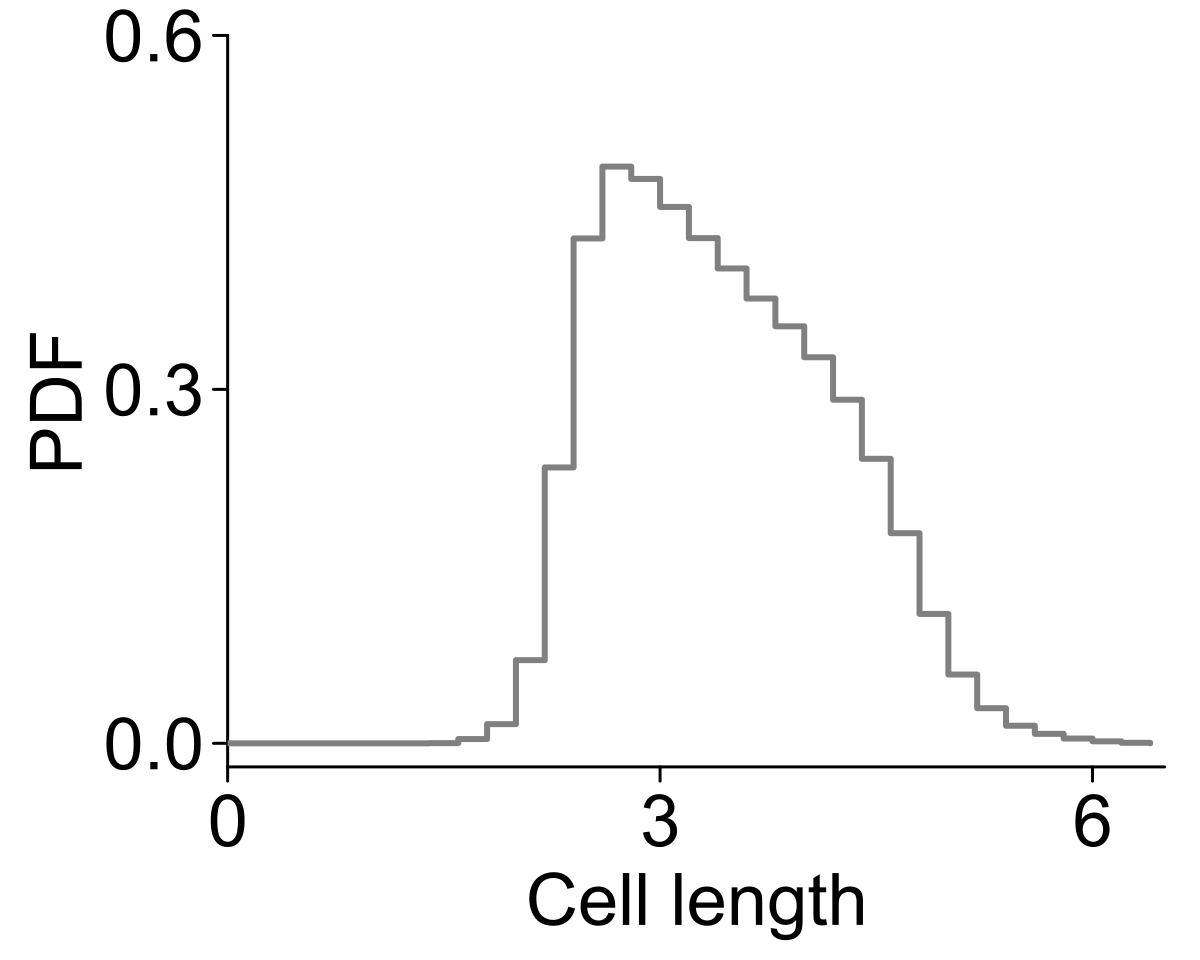

In [5]:
p1 = plot(;xlim=(0,6.5), xtick=[0,3,6],ylim=(-0.02,0.6),ytick=[0,0.3,0.6])
stephist!( p1, Lobs,bins=collect(0:0.2:6.5), normalize=:pdf,xlabel="Cell length", ylabel="PDF")


### Inference

In [6]:
isdiv, dtobs = annotate_sim_traj(Lobs, tobs);

In [7]:
n_func = 11;
Θ, Σ = gen_ortho_bases(Lobs, n_func-1);
Θdiv = Θ[isdiv,:];
Θdiv = sum(Θdiv, dims=1)[:];

_, coeffs_sparse = sparse_optimization(Θ, Θdiv, dtobs; EPSILON=1E-7, MAX_ITERS=20);

itr=1: -1183.1661206530744


itr=2: -1187.6519704043642


itr=3: -1187.1266277459913


itr=4: -1186.966859192896


itr=5: -1186.8459245668987


itr=6: -1186.7421554338266


... (5 outputs left out)

itr=12: -1186.089864864555


itr=13: -1186.0876817487951


itr=14: -1186.0873818157115


itr=15: -1186.0873427444492


In [8]:
display(coeffs_sparse)

11-element Vector{Float64}:
 -2.472180868390617
  2.5934741887958968
 -3.0829861768053527e-53
 -0.28169282582256533
 -1.7568261203434385e-17
  7.346915970364862e-62
  0.10703483189936985
  1.8967311121428563e-64
  0.6888891917967842
  2.2301948486740117e-62
  0.7515106109125566

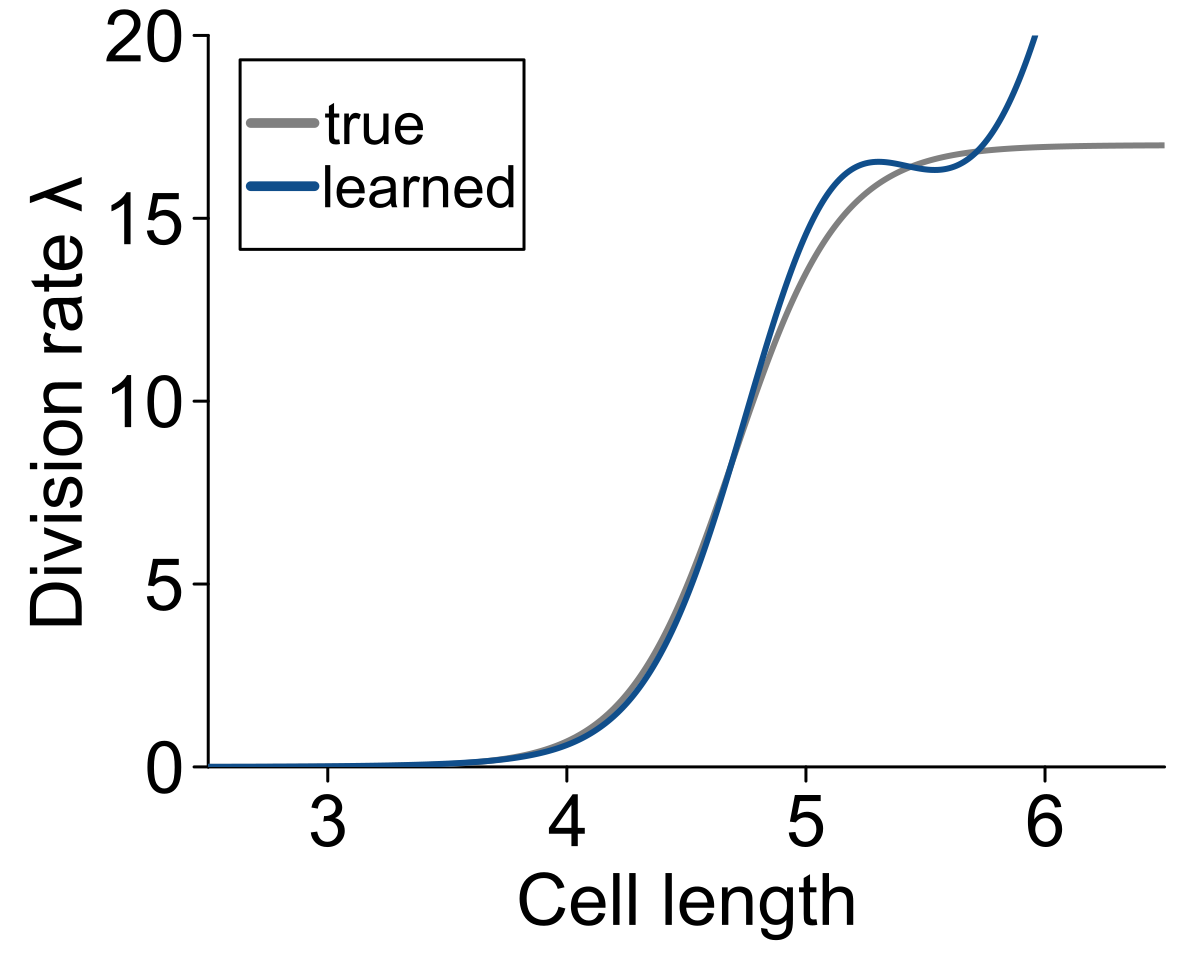

In [9]:
# # (optional)
# COEFF_TRESHOLD = 0.01
# coeffs_sparse[abs.(coeffs_sparse) .< COEFF_TRESHOLD] .= 0.0
# coeffs_dense[abs.(coeffs_dense) .< COEFF_TRESHOLD] .= 0.0;

uu = collect(2.5:0.01:6.5);
logλ_sparse = rec_ortho_bases(uu, Σ, coeffs_sparse);

p2 = plot(;legend=true, ylim=(0,20), ytick=collect(0:5:20), xlim=(2.5, 6.5), xtick=collect(3:6))
plot!(p2, uu, rate.(uu,0,0), label="true", ylabel="Division rate λ", xlabel="Cell length")
plot!(p2, uu, exp.(logλ_sparse),label="learned", lw=2, lc=:dodgerblue4)


### Resimulate

In [10]:
function rate2(u,p,t)
    Σ_ = p[1]
    coeffs_sparse_ = p[2]
    basis_func_ = p[3]
    return exp(rec_ortho_bases(u, Σ_, coeffs_sparse_, basis_func_)[1])
end

vrj2 = VariableRateJump(rate2, affect!)
oprob2 = ODEProblem(f, u0, (0.0,1000.0), (Σ, coeffs_sparse, Polynomial()))
jprob2 = JumpProblem(oprob2, Direct(), vrj2)
sol2 = solve(jprob2,Tsit5(),dtmax=0.01);

In [11]:
Lsim = Array(sol2')[:,1];
tsim = sol2.t;
isdiv_sim, _ = annotate_sim_traj(Lsim, tsim);

In [12]:
ApproximateTwoSampleKSTest(Lobs[isdiv],
                           Lsim[isdiv_sim])

Approximate two sample Kolmogorov-Smirnov test
----------------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.0210053

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.9304

Details:
    number of observations:   [1333,1333]
    KS-statistic:              0.5422854583884719


In [13]:
ApproximateTwoSampleKSTest(diff(tobs[isdiv]),
                           diff(tsim[isdiv_sim])
)

Approximate two sample Kolmogorov-Smirnov test
----------------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.0375375

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.3050

Details:
    number of observations:   [1332,1332]
    KS-statistic:              0.9687303228651604


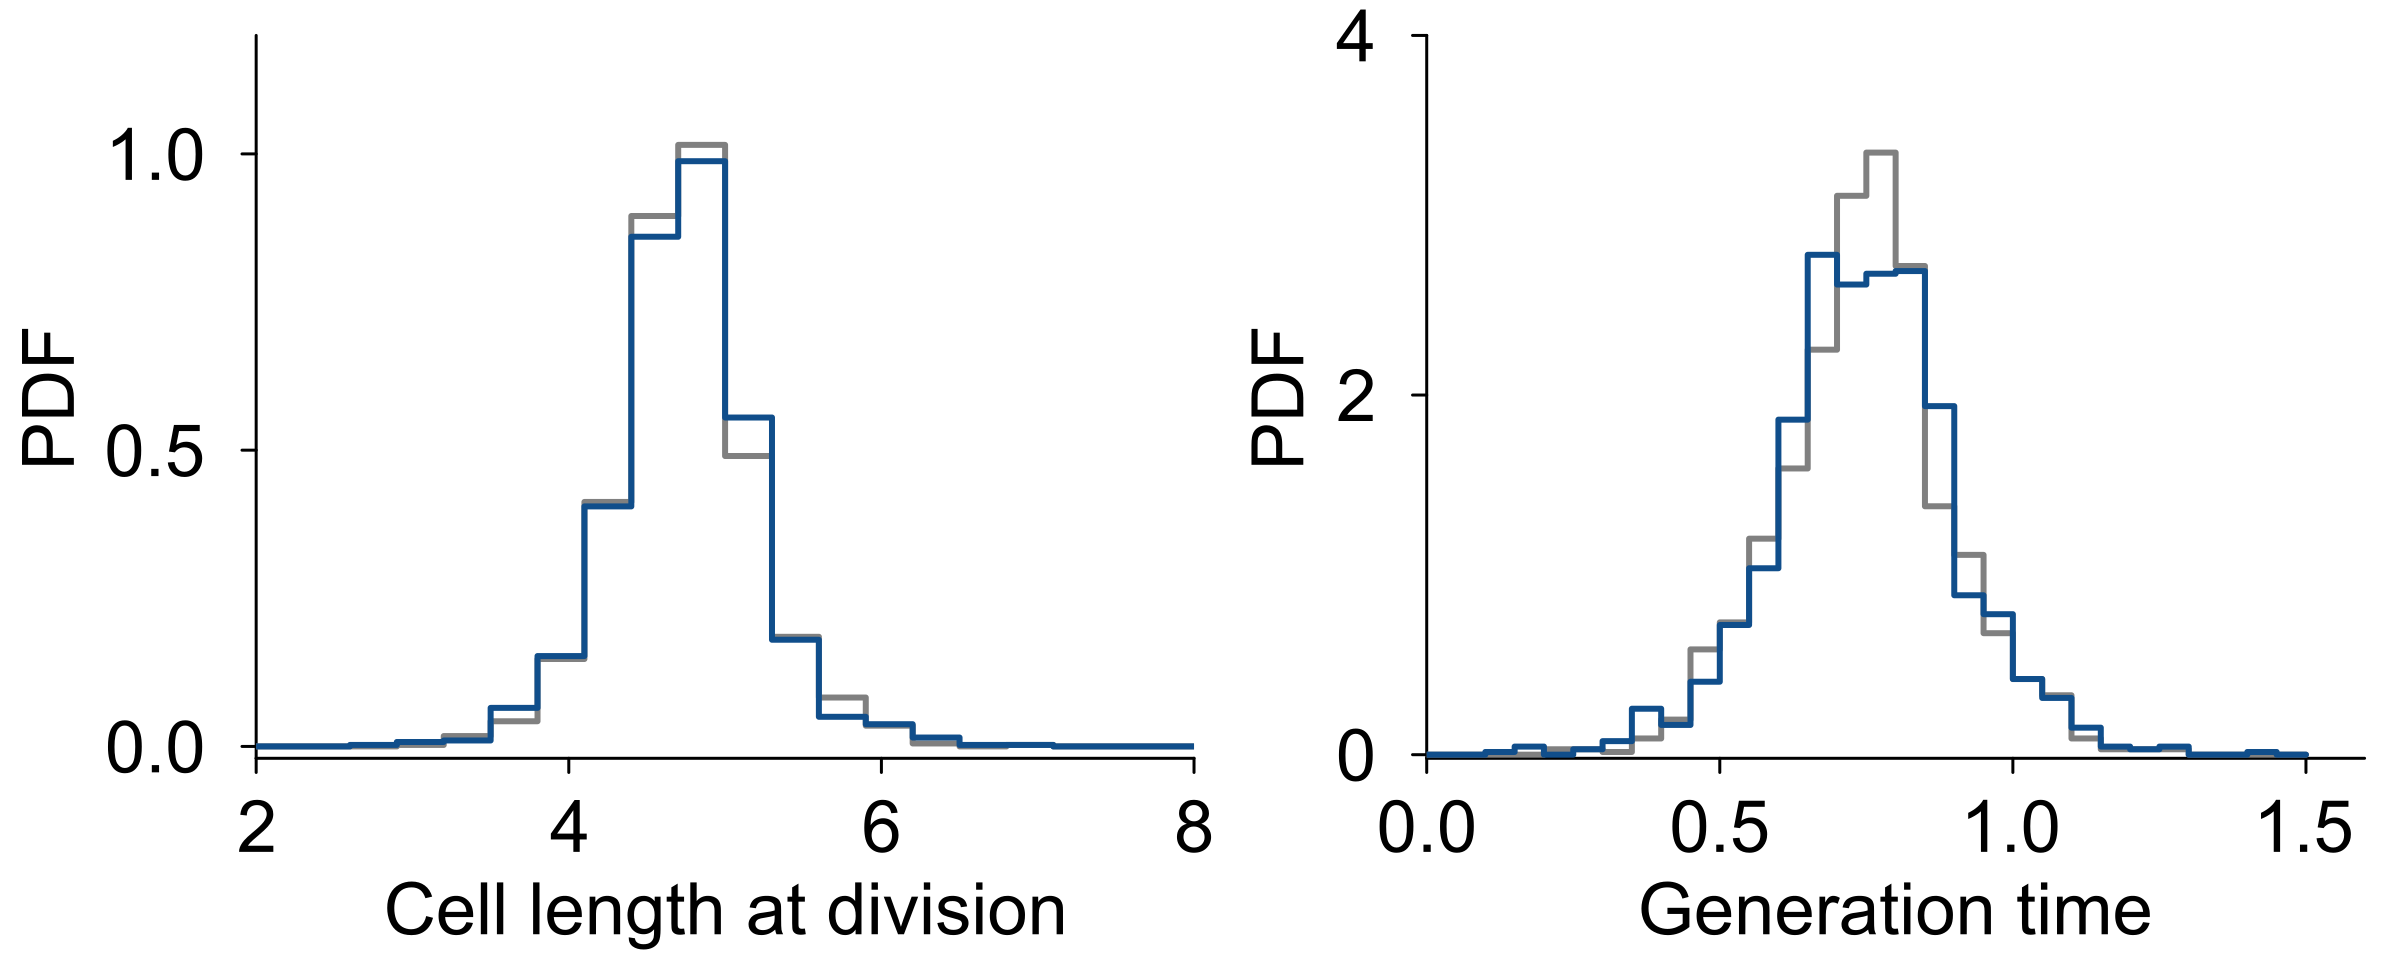

In [14]:
p3a = plot()
stephist!( p3a, Lobs[isdiv], normalize=:pdf,
         xlim=(2,8), xtick=[0,2,4,6,8],ylim=(-0.02,1.2),ytick=collect(0:0.5:2),bins=collect(2:0.3:8),
         ylabel="PDF", xlabel="Cell length at division")
stephist!( p3a, Lsim[isdiv_sim], normalize=:pdf, lc=:dodgerblue4,  bins=collect(2:0.3:8))
p3a

p3b = plot()
stephist!( p3b, diff(tobs[isdiv]), normalize=:pdf,
        xlim=(0,1.6), xtick=collect(0:0.5:1.5),ylim=(-0.02,4),ytick=[0,2,4], bins=collect(0:0.05:1.5),
        ylabel="PDF", xlabel="Generation time" )
stephist!( p3b, diff(tsim[isdiv_sim]), normalize=:pdf, lc=:dodgerblue4, bins=collect(0:0.05:1.5))

ll = @layout [a b]
plot(p3a, p3b, layout=ll, size=(800, 320), bottommargin=7Plots.mm,leftmargin=bottommargin=5Plots.mm)

### Looking at joint probability

In [15]:
using StatsBase
hedges = collect(3:0.25:6.5);
hbins = 0.5*( hedges[1:end-1] + hedges[2:end] )
dhedges = mean( diff(hedges) );
h1 = fit(Histogram, Lobs[isdiv], hedges)
h2 = fit(Histogram, (Lobs[isdiv][1:end-1], Lobs[isdiv][2:end]), (hedges,hedges));

In [16]:
h1_normalize = h1.weights / sum(h1.weights) / dhedges
h2_normalize = h2.weights / sum(h2.weights) / dhedges^2

svd_h1 = svd(h1_normalize * h1_normalize');
svd_h2 = svd(h2_normalize);

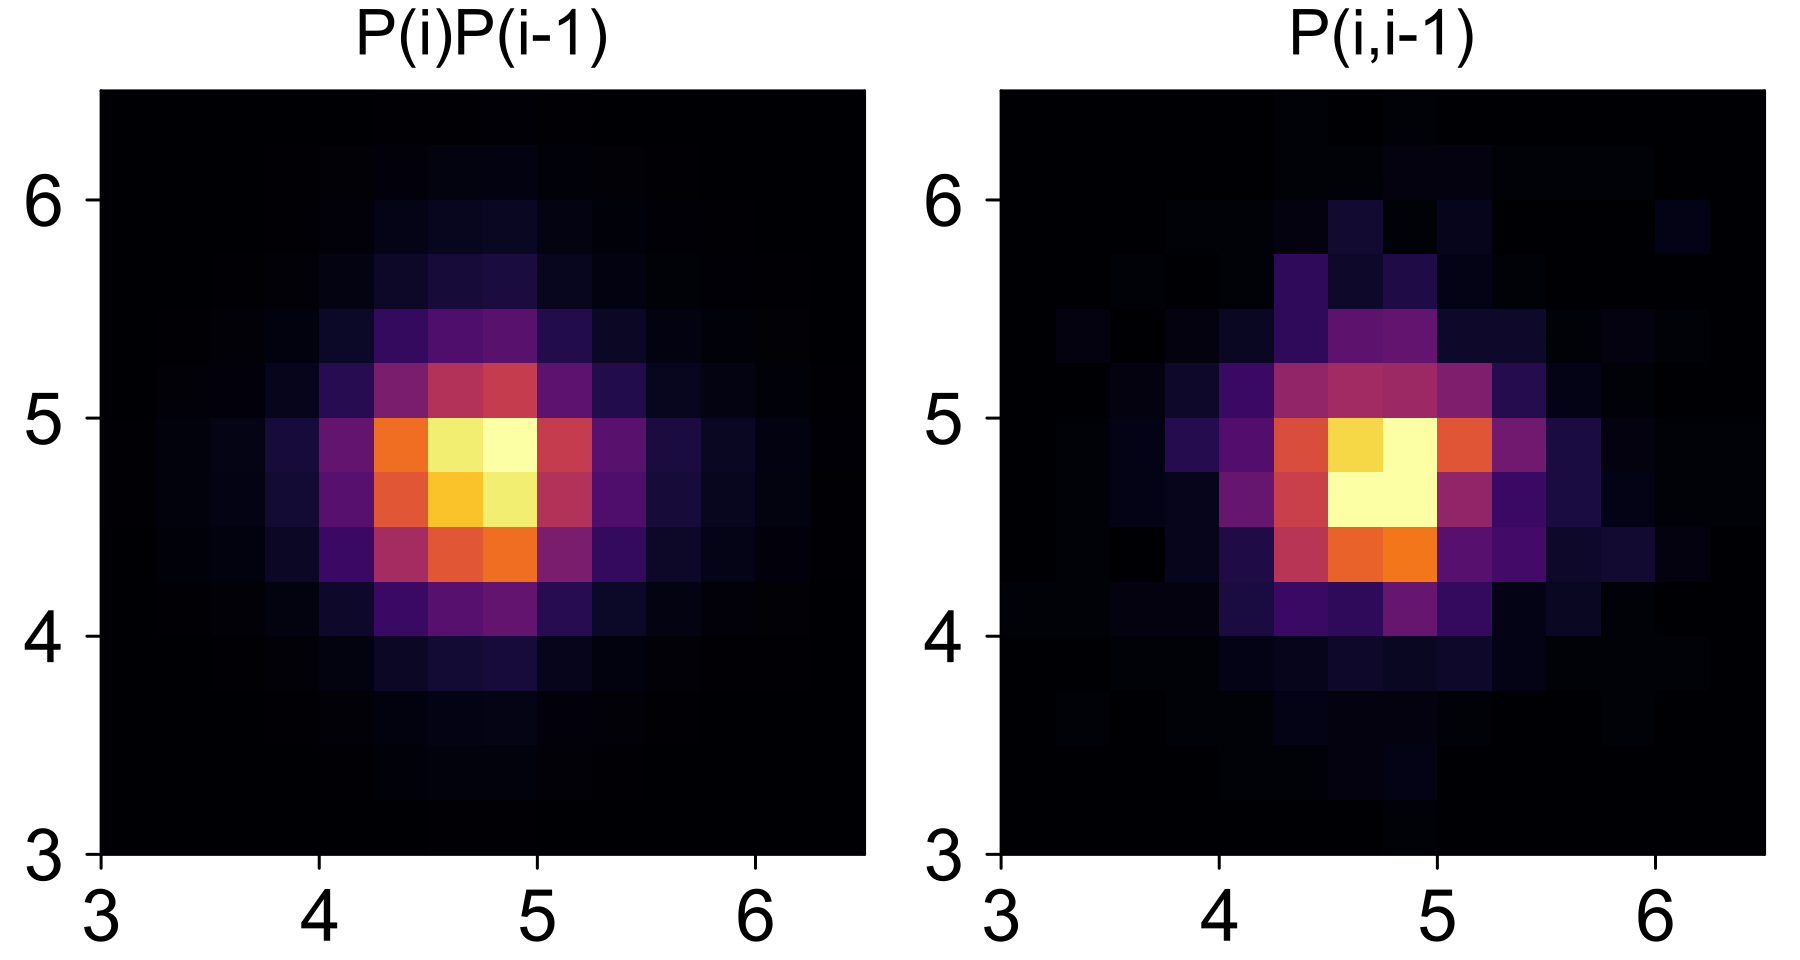

In [17]:
p_h1 = plot(; aspect_ratio=1, framestyle=:box, xlim=(3,6.5), ylim=(3,6.5), xtick=collect(3:6), ytick=collect(3:6), title="P(i)P(i-1)" )
heatmap!( p_h1, hbins, hbins, h1_normalize * h1_normalize', clim=(0,1)) 

p_h2 = plot(; aspect_ratio=1, framestyle=:box, xlim=(3,6.5), ylim=(3,6.5), xtick=collect(3:6), ytick=collect(3:6), title="P(i,i-1)" )
heatmap!( p_h2, hbins, hbins, h2_normalize, clim=(0,1)) 

plot(p_h1, p_h2, layout = ll, size=(600,320))

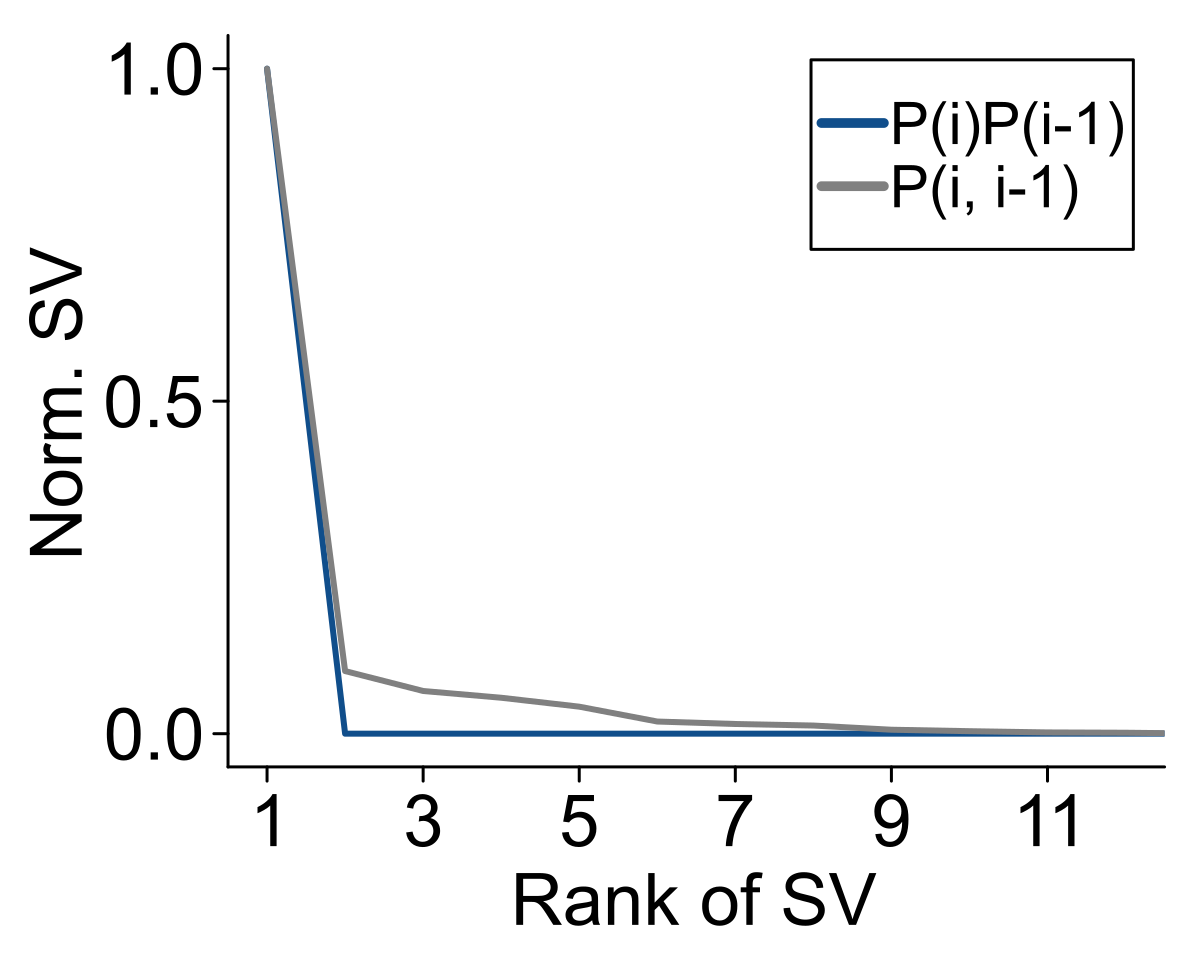

In [18]:
p_svd_1 = plot(; xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)
plot!( p_svd_1, svd_h1.S ./ svd_h1.S[1], lc=:dodgerblue4, label="P(i)P(i-1)" )
plot!( p_svd_1, svd_h2.S ./ svd_h2.S[1],  label="P(i, i-1)" )


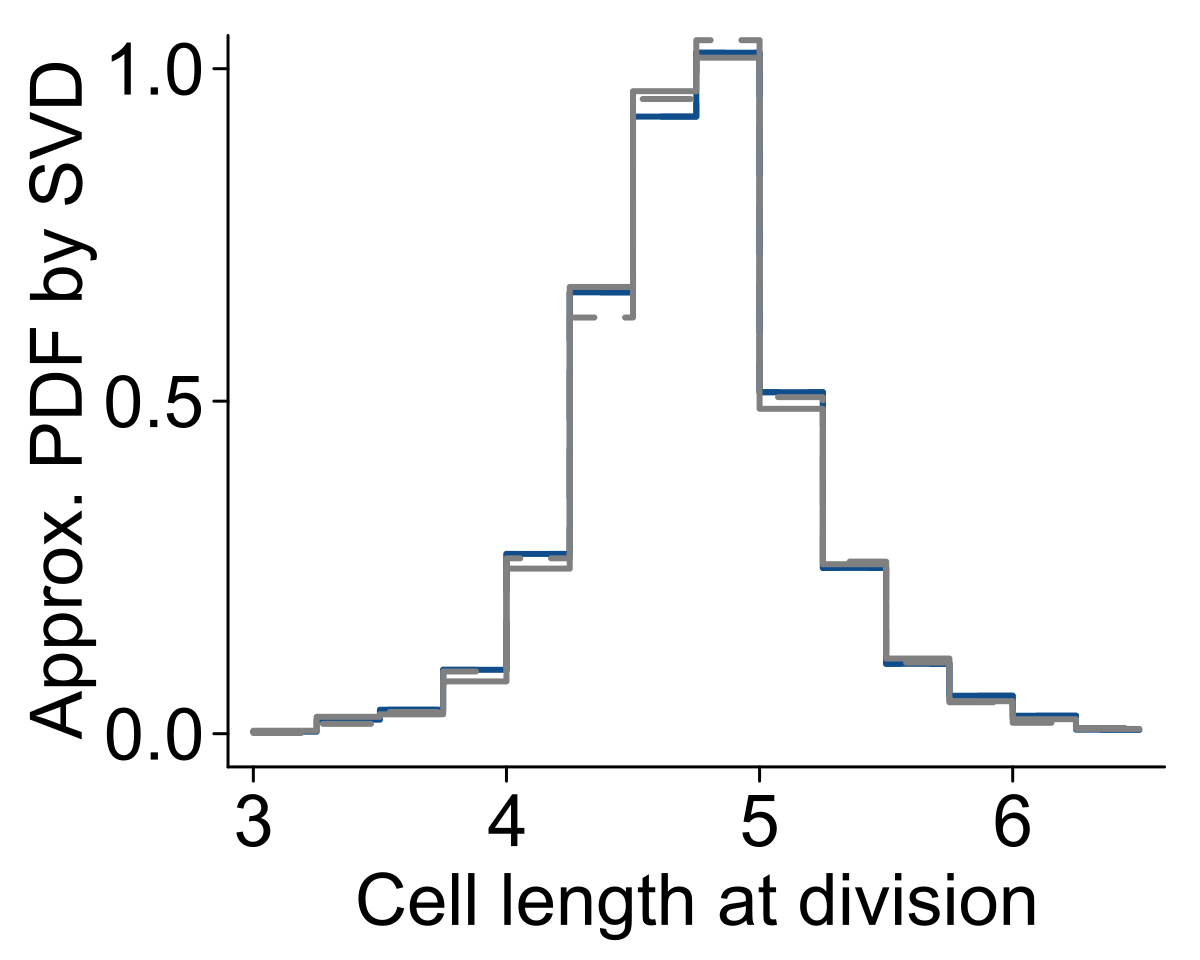

In [19]:
yU_h1 = svd_h1.U[:,1] * sqrt(svd_h1.S[1])
yV_h1 = svd_h1.V[:,1] * sqrt(svd_h1.S[1])

yU_h2 = svd_h2.U[:,1] * sqrt(svd_h2.S[1])
yV_h2 = svd_h2.V[:,1] * sqrt(svd_h2.S[1])

function plot_histogram!( pp, _hedges::Vector{T}, _y::Vector{T}; plot_args...) where T
    _index_edges = vcat([[i,i] for i in 1:length(_hedges)]...);
    _index_y = vcat([[i,i] for i in 1:length(_y)]...);
    plot!(pp, _hedges[_index_edges[2:end-1]], _y[_index_y]; plot_args...)
    nothing
end

p_svd_2 = plot(; ylim=(-0.05,1.05), xlim=(2.9,6.6), xtick=collect(3:6), ytick=collect(0:0.5:1), xlabel="Cell length at division", ylabel="Approx. PDF by SVD")
plot_histogram!(p_svd_2, hedges, abs.(yU_h1); lc=:dodgerblue4)
plot_histogram!(p_svd_2, hedges, abs.(yV_h1); ls=:dash, lc=:dodgerblue4)
plot_histogram!(p_svd_2, hedges, abs.(yU_h2))
plot_histogram!(p_svd_2, hedges, abs.(yV_h2); ls=:dash)
p_svd_2